# Séance 1 — Découverte des données et construction des variables

Objectifs de la séance (cf. `instructions/BE_CS1_instructions.ipynb`) :
1. Charger les traces brutes
2. Premières statistiques (navigateurs, distribution de la cible, longueur des sessions)
3. Repérer les valeurs aberrantes
4. Construire un tableau de *features* (une ligne = une session)
5. Premières visualisations

> Les données Kaggle doivent être placées dans `data/` à la racine du dépôt (non versionné).

In [1]:
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = Path("../data")  # le notebook est dans Complémentaire/, les données à la racine du dépôt
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

## 1. Chargement des données brutes

Plutôt que `pd.read_csv` (qui crée ~14 000 colonnes remplies de NaN à cause des sessions très longues),
on lit chaque ligne comme une **liste d'éléments**. On précise `encoding="utf-8"` sinon les accents sont mal lus sous Windows.

In [2]:
def read_sessions(name: str) -> pd.DataFrame:
    """Lit train/test : une ligne = une session, les actions sont stockées dans une liste."""
    rows = []
    with open(DATA_DIR / f"{name}.csv", encoding="utf-8") as f:
        for line in f:
            parts = line.rstrip("\n").split(",")
            if name == "train":
                rows.append({"util": parts[0], "navigateur": parts[1], "trace": parts[2:]})
            else:
                rows.append({"navigateur": parts[0], "trace": parts[1:]})
    return pd.DataFrame(rows)

train = read_sessions("train")
test = read_sessions("test")
print("train :", train.shape, "| test :", test.shape)
train.head()

train : (3279, 3) | test : (324, 2)


,util,navigateur,trace
0,nuh,Firefox,[Création d'un écran(infologic.core.accueil.Ac...
1,muz,Google Chrome,[Création d'un écran(infologic.core.gui.contro...
2,zrx,Microsoft Edge,[Affichage d'une dialogue(infologic.core.gui.c...
3,pou,Firefox,[Création d'un écran(infologic.core.gui.contro...
4,ald,Google Chrome,[Affichage d'une dialogue(infologic.acti.modul...


In [3]:
# Exemple de session brute (début)
print(train.loc[0, "util"], train.loc[0, "navigateur"])
train.loc[0, "trace"][:25]

nuh Firefox


["Création d'un écran(infologic.core.accueil.AccueilController)",
 "Affichage d'une dialogue",
 "Exécution d'un bouton",
 "Fermeture d'une dialogue",
 "Affichage d'une dialogue",
 "Exécution d'un bouton",
 "Fermeture d'une dialogue",
 "Création d'un écran(infologic.core.gui.controllers.nested.InputFormNestedWindow)",
 't5',
 "Exécution d'un bouton(MAINT)",
 "Affichage d'une dialogue",
 "Fermeture d'une dialogue",
 'Double-clic',
 "Exécution d'un bouton",
 "Lancement d'une stat(infologic.core.gui.controllers.nested.homeview.InputFormHomeView)",
 "Affichage d'un toast",
 "Lancement d'une stat(infologic.core.gui.controllers.nested.homeview.InputFormHomeView)",
 't10',
 "Affichage d'une dialogue(MAINT)",
 "Exécution d'un bouton",
 "Fermeture d'une dialogue",
 't15',
 'Double-clic',
 "Lancement d'une action générique",
 "Affichage d'une dialogue"]

## 2. Premières statistiques

### Navigateurs

In [4]:
pd.concat({"train": train["navigateur"].value_counts(normalize=True),
           "test": test["navigateur"].value_counts(normalize=True)}, axis=1).round(3)

,train,test
navigateur,,
Firefox,0.447,0.454
Google Chrome,0.408,0.410
Microsoft Edge,0.138,0.130
Opera,0.007,0.006


In [5]:
# Nombre de sessions par utilisateur (lignes) et par navigateur (colonnes)
browsers_per_user = pd.crosstab(train["util"], train["navigateur"])
print("Utilisateurs utilisant plusieurs navigateurs :", (browsers_per_user.gt(0).sum(axis=1) > 1).sum(),
      "/", len(browsers_per_user))
browsers_per_user.head(10)

Utilisateurs utilisant plusieurs navigateurs : 0 / 247


navigateur,Firefox,Google Chrome,Microsoft Edge,Opera
util,,,,
aho,0,10,0,0
ajo,13,0,0,0
akx,0,14,0,0
ald,0,15,0,0
ats,12,0,0,0
avt,15,0,0,0
azn,0,4,0,0
azo,0,10,0,0
azx,0,10,0,0


*À interpréter :* si la plupart des utilisateurs n'utilisent qu'un seul navigateur, cette variable est très discriminante.

### Distribution de la variable cible `util`

Nombre d'utilisateurs : 247
count    247.0
mean      13.3
std        8.9
min        4.0
25%        7.0
50%       12.0
75%       16.0
max       75.0
Name: count, dtype: float64


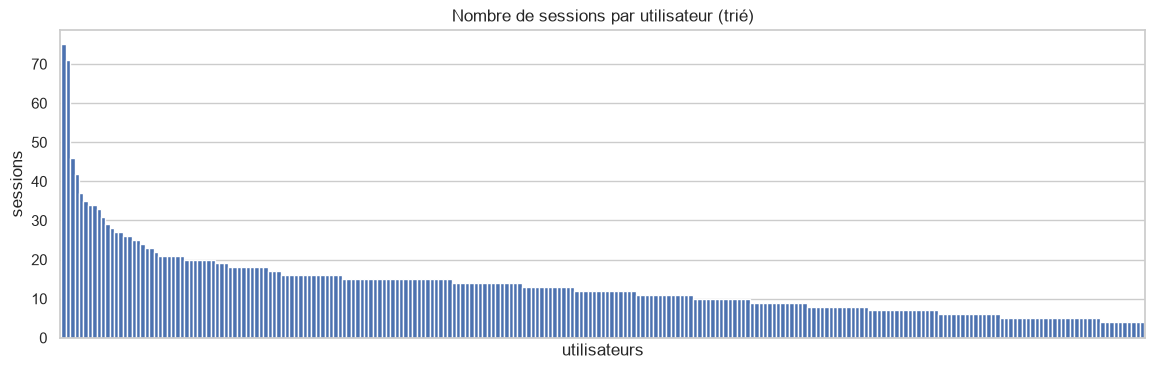

In [6]:
y_counts = train["util"].value_counts()
print("Nombre d'utilisateurs :", y_counts.size)
print(y_counts.describe().round(1))

fig, ax = plt.subplots(figsize=(14, 4))
y_counts.plot.bar(ax=ax, width=1)
ax.set_xticks([])
ax.set(title="Nombre de sessions par utilisateur (trié)", xlabel="utilisateurs", ylabel="sessions")
plt.show()

*À interpréter :* les classes sont très déséquilibrées (de quelques sessions à plusieurs dizaines).
Conséquences pour la suite : métrique F1 (pas seulement l'accuracy), découpage train/validation **stratifié**,
éventuellement `class_weight="balanced"`.

## 3. Parsing des traces

Chaque élément de la trace est soit un **marqueur temporel** `tXX` (toutes les 5 s), soit une **action** qui peut contenir :
- `(...)` : l'écran
- `<...>` : la configuration d'écran
- `$...$` : la chaîne de la fiche
- un `1` final : mode modification

In [7]:
RE_TIME = re.compile(r"^t(\d+)$")
RE_ECRAN = re.compile(r"\((.*?)\)")
RE_CONF = re.compile(r"<(.*?)>")
RE_CHAINE = re.compile(r"\$(.*?)\$")

def parse_action(token: str) -> dict:
    """Découpe une action en : action de base, écran, configuration, chaîne, mode modification."""
    ecran = RE_ECRAN.search(token)
    conf = RE_CONF.search(token)
    chaine = RE_CHAINE.search(token)
    modif = token.endswith("1")
    base = re.split(r"[(<$]", token, maxsplit=1)[0]
    if modif and base.endswith("1"):
        base = base[:-1]
    return {
        "base": base.strip(),
        "ecran": ecran.group(1) if ecran else None,
        "conf": conf.group(1) if conf else None,
        "chaine": chaine.group(1) if chaine else None,
        "modif": modif,
    }

parse_action("Saisie dans un champ(MAINT)<DEF_03/24>$GP$1")

{'base': 'Saisie dans un champ',
 'ecran': 'MAINT',
 'conf': 'DEF_03/24',
 'chaine': 'GP',
 'modif': True}

In [8]:
# Inventaire des actions de base sur tout le train
action_counter = Counter(
    parse_action(tok)["base"]
    for trace in train["trace"] for tok in trace if not RE_TIME.match(tok)
)
print(len(action_counter), "actions de base différentes")
pd.Series(action_counter).sort_values(ascending=False).head(30)

35 actions de base différentes


Exécution d'un bouton                            510645
Saisie dans un champ                             265633
Sélection d'un écran                             206813
Fermeture d'une dialogue                         171026
Affichage d'une dialogue                         168928
Lancement d'une action générique                 115283
Sélection d’un onglet                            109209
Raccourci                                         82176
Création d'un écran                               76930
Chainage                                          68194
Double-clic                                       67992
Retour sur un écran                               61946
Affichage d'un toast                              52091
Clic sur une grille d'historique de recherche     50273
Entrée en saisie dans un formulaire               39276
Filtrage / Tri                                    37628
Sélection d'un flag                               32252
Lancement d'une stat                            

## 4. Longueur des sessions et valeurs aberrantes

In [9]:
def session_stats(trace):
    times = [int(m.group(1)) for tok in trace if (m := RE_TIME.match(tok))]
    n_actions = sum(1 for tok in trace if not RE_TIME.match(tok))
    return pd.Series({"n_actions": n_actions, "duree_s": max(times, default=0)})

lengths = train["trace"].apply(session_stats)
lengths.describe(percentiles=[.01, .05, .5, .95, .99]).round(1)

,n_actions,duree_s
count,3279.0,3279.0
mean,692.4,751.5
std,1005.9,1006.3
min,0.0,5.0
1%,45.8,45.0
5%,71.0,80.0
50%,340.0,395.0
95%,2386.9,2590.5
99%,4697.2,4466.6
max,11977.0,11790.0


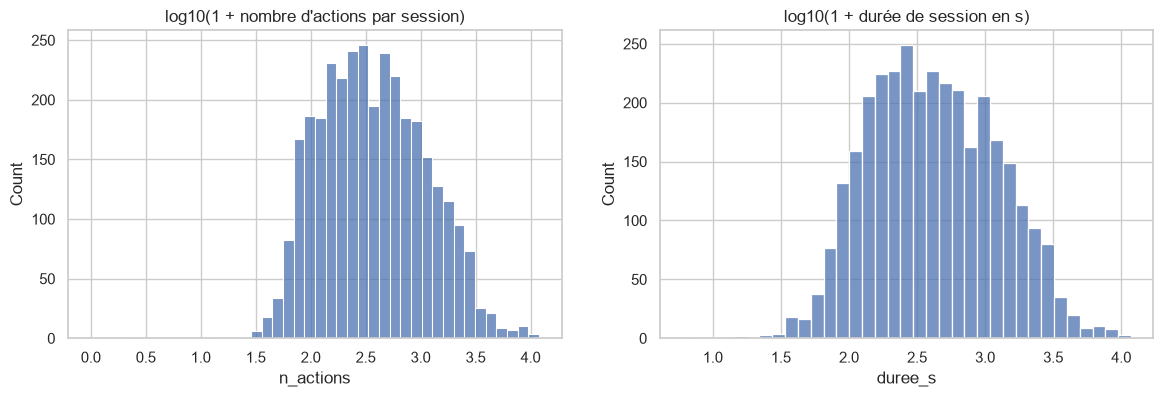

Sessions sans aucune action : 1
Sessions avec ≤ 2 actions : 3
Sessions > 99e percentile d'actions : 33


In [10]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(np.log10(lengths["n_actions"] + 1), ax=axs[0]).set(title="log10(1 + nombre d'actions par session)")
sns.histplot(np.log10(lengths["duree_s"] + 1), ax=axs[1]).set(title="log10(1 + durée de session en s)")
plt.show()

print("Sessions sans aucune action :", (lengths["n_actions"] == 0).sum())
print("Sessions avec ≤ 2 actions :", (lengths["n_actions"] <= 2).sum())
print("Sessions > 99e percentile d'actions :", (lengths["n_actions"] > lengths["n_actions"].quantile(.99)).sum())

*À décider en groupe :* les sessions très courtes contiennent peu d'information ; les sessions très longues sont rares
mais légitimes. Plutôt que de les supprimer, on utilise des variables **normalisées** (fréquences, moyennes par fenêtre)
et des transformations log. Attention : on ne peut **pas** supprimer de lignes du jeu de test (il faut une prédiction par ligne).

## 5. Construction des features

Une ligne = une session. Variables construites :
- **volume / rythme** : nombre d'actions, durée, actions par fenêtre de 5 s (moyenne, écart-type, max), actions dans les 5 premières secondes
- **diversité** : nombre d'actions, d'écrans, de configurations, de chaînes distinctes ; part d'actions en mode modification
- **éléments favoris** : écran, configuration et chaîne les plus utilisés (catégoriels, à encoder en séance 2)
- **profil d'actions** : fréquence relative de chaque action de base (`act_...`)
- **navigateur** : one-hot encoding

In [11]:
ACTIONS = sorted(action_counter)  # vocabulaire figé sur le train

def most_common(values):
    values = [v for v in values if v]
    return Counter(values).most_common(1)[0][0] if values else "AUCUN"

def build_features(trace) -> dict:
    parsed, per_window, current = [], [], 0
    for tok in trace:
        if RE_TIME.match(tok):
            per_window.append(current)
            current = 0
        else:
            parsed.append(parse_action(tok))
            current += 1
    per_window.append(current)  # actions après le dernier marqueur
    n = len(parsed)
    times = [int(m.group(1)) for tok in trace if (m := RE_TIME.match(tok))]

    feats = {
        "n_actions": n,
        "log_n_actions": np.log1p(n),
        "duree_s": max(times, default=0),
        "n_fenetres": len(per_window),
        "actions_par_fenetre_moy": np.mean(per_window),
        "actions_par_fenetre_std": np.std(per_window),
        "actions_par_fenetre_max": max(per_window),
        "actions_5_premieres_s": per_window[0],
        "n_actions_distinctes": len({p["base"] for p in parsed}),
        "n_ecrans_distincts": len({p["ecran"] for p in parsed if p["ecran"]}),
        "n_confs_distinctes": len({p["conf"] for p in parsed if p["conf"]}),
        "n_chaines_distinctes": len({p["chaine"] for p in parsed if p["chaine"]}),
        "part_modif": np.mean([p["modif"] for p in parsed]) if n else 0.0,
        "ecran_top": most_common(p["ecran"] for p in parsed),
        "conf_top": most_common(p["conf"] for p in parsed),
        "chaine_top": most_common(p["chaine"] for p in parsed),
    }
    counts = Counter(p["base"] for p in parsed)
    for a in ACTIONS:
        feats[f"act_{a}"] = counts.get(a, 0) / n if n else 0.0
    return feats

def make_feature_table(df: pd.DataFrame) -> pd.DataFrame:
    X = pd.DataFrame([build_features(t) for t in df["trace"]], index=df.index)
    nav = pd.get_dummies(df["navigateur"], prefix="nav", dtype=int)
    return pd.concat([X, nav], axis=1)

X_train = make_feature_table(train)
X_test = make_feature_table(test).reindex(columns=X_train.columns, fill_value=0)
y_train = train["util"]
print("X_train :", X_train.shape, "| X_test :", X_test.shape)
X_train.iloc[:5, :17]

X_train : (3279, 55) | X_test : (324, 55)


,n_actions,log_n_actions,duree_s,n_fenetres,actions_par_fenetre_moy,actions_par_fenetre_std,actions_par_fenetre_max,actions_5_premieres_s,n_actions_distinctes,n_ecrans_distincts,n_confs_distinctes,n_chaines_distinctes,part_modif,ecran_top,conf_top,chaine_top,act_Action de table
0,2514,7.830028,2905,615,4.087805,3.661103,22,8,19,7,3,2,0.001591,MAINT,DEF_03/24,JCP,0.004375
1,90,4.510860,230,47,1.914894,1.268770,6,2,11,5,2,2,0.288889,infologic.orga.modules.OR_FICHIERTRAVAIL.Insta...,TELEM_MINIMAL,DB,0.000000
2,608,6.411818,750,159,3.823899,3.740875,22,9,21,17,7,2,0.082237,DEMTEST,DEF_07/23,MES,0.009868
3,886,6.787845,1445,314,2.821656,2.856445,22,1,19,10,4,1,0.072235,MAINT,DEF_03/24,JCP,0.007901
4,173,5.159055,275,61,2.836066,2.759070,15,1,14,8,4,2,0.011561,MAINT,INSTALLATEUR,GP,0.017341


In [12]:
# Nombre de valeurs distinctes des variables catégorielles « favorites »
X_train[["ecran_top", "conf_top", "chaine_top"]].nunique()

ecran_top     116
conf_top      112
chaine_top     61
dtype: int64

In [13]:
# Sauvegarde pour la séance 2 (data/ n'est pas versionné)
X_train.assign(util=y_train).to_pickle(DATA_DIR / "features_train.pkl")
X_test.to_pickle(DATA_DIR / "features_test.pkl")

## 6. Visualisations

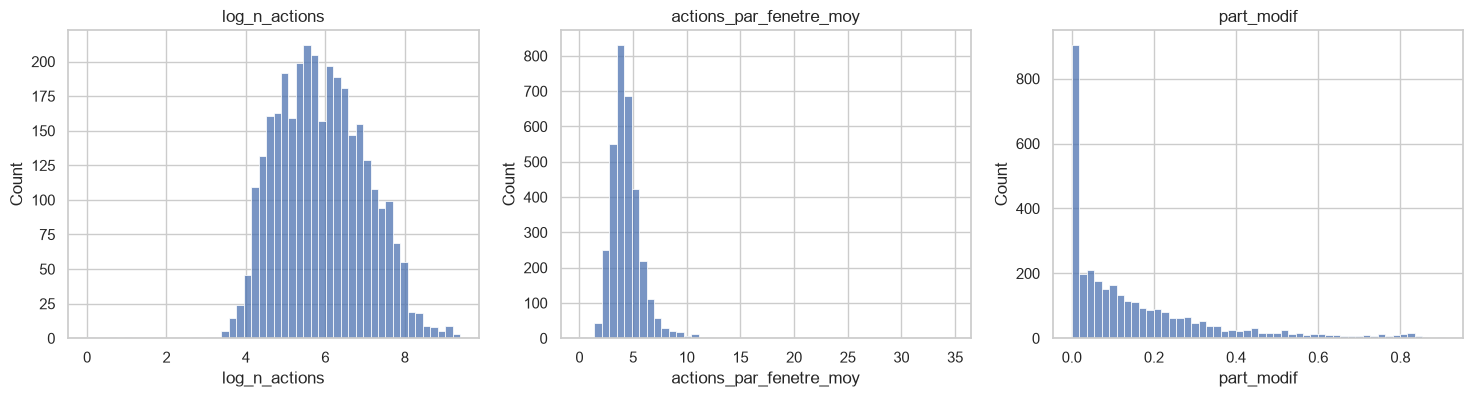

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axs, ["log_n_actions", "actions_par_fenetre_moy", "part_modif"]):
    sns.histplot(X_train[col], ax=ax, bins=50).set(title=col)
plt.show()

*À interpréter :* forme des distributions, asymétries, éventuels pics.

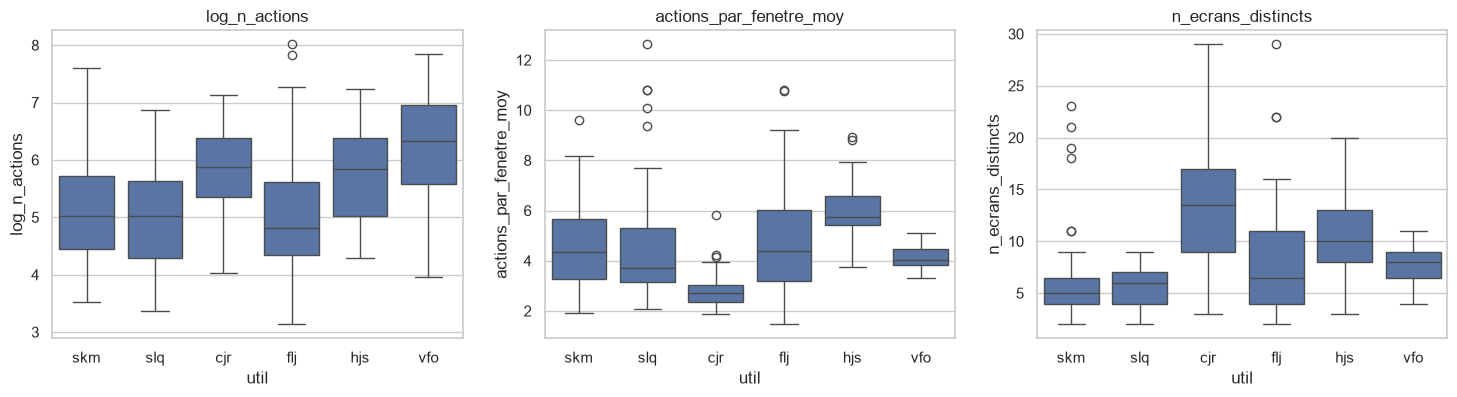

In [15]:
# Distribution de quelques features pour les utilisateurs les plus fréquents
top_users = y_counts.index[:6]
subset = X_train.assign(util=y_train)[lambda d: d["util"].isin(top_users)]

fig, axs = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axs, ["log_n_actions", "actions_par_fenetre_moy", "n_ecrans_distincts"]):
    sns.boxplot(data=subset, x="util", y=col, order=top_users, ax=ax).set(title=col)
plt.show()

*À interpréter :* si les boîtes sont bien séparées d'un utilisateur à l'autre, la variable est discriminante.

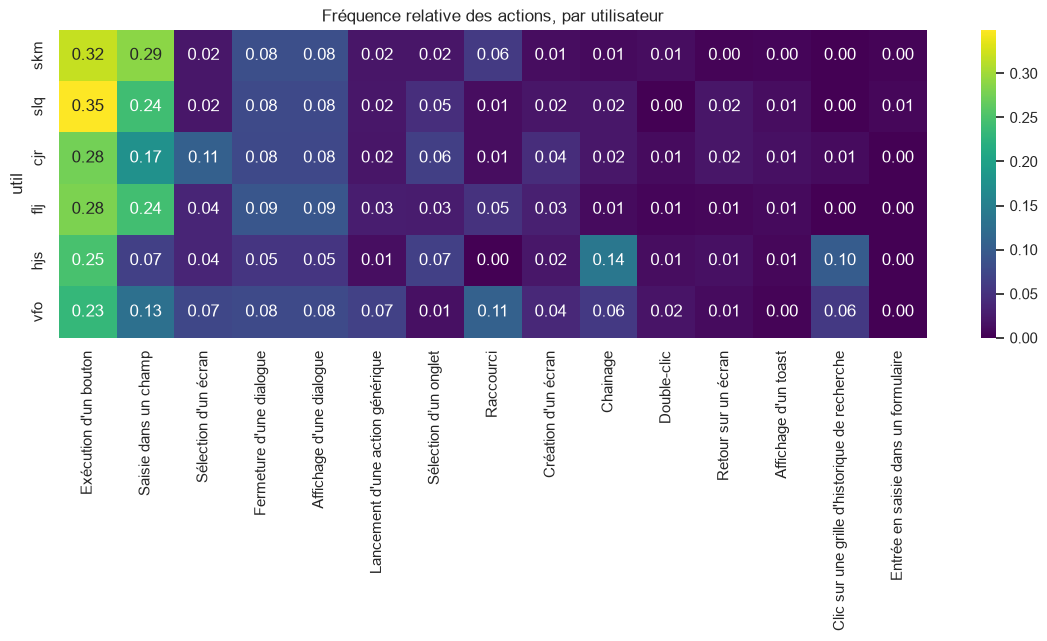

In [16]:
# Profil d'actions moyen des utilisateurs les plus fréquents (actions les plus courantes)
act_cols = [f"act_{a}" for a, _ in action_counter.most_common(15)]
profile = subset.groupby("util")[act_cols].mean().loc[top_users]
profile.columns = [c.removeprefix("act_") for c in profile.columns]

plt.figure(figsize=(14, 4))
sns.heatmap(profile, cmap="viridis", annot=True, fmt=".2f")
plt.title("Fréquence relative des actions, par utilisateur")
plt.show()

## Pistes pour la séance 2
- Encoder `ecran_top`, `conf_top`, `chaine_top` (one-hot sur les modalités fréquentes, ou fréquences de tous les écrans/chaînes façon *sac de mots*)
- Essayer une représentation **TF-IDF** des traces (`TfidfVectorizer` sur les actions / écrans / chaînes, avec n-grammes)
- Découpage train/validation stratifié, premiers modèles (régression logistique, Random Forest) évalués en F1 macro